# Query maps on breast

The poster's `program_map` for several kinds of query: the whole section with one cell class highlighted, the
query's `TOP` closest index tiles boxed, and the query tile (if the query comes from a tile) in a thick black box.
Beside each map, the highlighted class's share of the cells in the top tiles against the section.

Queries (all searched exactly, Spindle or Spindle-partial):

1. **Whole tile**: a held-out tile's full covariance, `Spindle` (d_B).
2. **Gene set from a tile, a block of the layout**: the same tile's covariance cut to one block's genes (`tile_query`),
   `SpindlePartial` (d_B^S).
3. **Gene set from a tile, a curated list**: the same tile cut to a gene list (`tile_query`).
4. **Gene list alone**: the template query of each breast signature (`template_query`, Methods Eq. signature).


In [5]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import PatchCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle

ROOT = Path.cwd().resolve()
while not (ROOT / "datasets.yaml").exists():
    ROOT = ROOT.parent
for p in (ROOT / "src", ROOT):
    if str(p) not in sys.path:
        sys.path.insert(0, str(p))
import paths
import spindle_dev as sd

KEY, SEED, TEST_RATIO = "breast_cancer", 0, 0.1
TOP = 50          # tiles boxed per query
MIN_CELLS = 100   # query tiles: at least this many cells

## Section, tiles and the index

In [6]:
adata = sd.load_adata(paths.dataset_path(KEY))
tiles, covs, genes = sd.prepare_tiles(adata, max_genes=paths.dataset_max_genes(KEY))
genes = np.asarray(genes).astype(str)
train, test = sd.split_tiles(len(tiles), seed=SEED, test_ratio=TEST_RATIO)
tr_covs = [covs[i] for i in train]

layout = sd.build_layout([tiles[i] for i in train], tr_covs, genes, adata.n_obs)
whole = sd.Spindle(layout, tr_covs)
part = sd.SpindlePartial(layout, tr_covs)
omega = sd.variance_quantiles(tr_covs)
labels = np.asarray(layout.labels).astype(int)
print(f"{adata.n_obs} cells, {len(genes)} genes, {len(tiles)} tiles ({len(train)} index, {len(test)} held out), "
      f"{len(set(labels))} niches")

[2026-10-27 04:38:58,984] INFO spindle_dev.preprocessing: build_quadtree_tiles: dropping 37 low-density tile(s) (1865 spots)
/home/NAShome/ghoss18/miniforge3/envs/sparta_spatial/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
[2026-10-27 04:39:07,734] INFO spindle_dev.layout: Leiden resolution 0.20: 4 niches, sizes [664, 493, 411, 272]
[2026-10-27 04:39:08,762] INFO spindle_dev.layout: Niche 0: 16 blocks
[2026-10-27 04:39:08,808] INFO spindle_dev.layout: Niche 1: 15 blocks
[2026-10-27 04:39:08,861] INFO spindle_dev.layout: Niche 2: 17 blocks
[2026-10-27 04:39:08,909] INFO spindle_dev.layout: Niche 3: 15 blocks


159226 cells, 313 genes, 2044 tiles (1840 index, 204 held out), 4 niches


## Cell classes

The section's annotation (`Cluster`) grouped into 8 classes, as in the poster and Fig 6. A tile's composition is
over its cells.

In [7]:
CLASSES = [
    ("Invasive tumour", "#CC3311", ["Invasive_Tumor", "Prolif_Invasive_Tumor", "T_Cell_&_Tumor_Hybrid"]),
    ("DCIS", "#EE7733", ["DCIS_1", "DCIS_2"]),
    ("Myoepithelial", "#882255", ["Myoepi_ACTA2+", "Myoepi_KRT15+"]),
    ("Stromal", "#DDCC77", ["Stromal", "Stromal_&_T_Cell_Hybrid"]),
    ("Endothelial / perivascular", "#44AA99", ["Endothelial", "Perivascular-Like"]),
    ("Myeloid", "#0077BB", ["Macrophages_1", "Macrophages_2", "IRF7+_DCs", "LAMP3+_DCs", "Mast_Cells"]),
    ("T cells", "#33BBEE", ["CD4+_T_Cells", "CD8+_T_Cells"]),
    ("B cells", "#117733", ["B_Cells"]),
]
CLASS_NAMES = [c[0] for c in CLASSES]
CLASS_COLORS = dict((n, col) for n, col, _ in CLASSES)

to_class = {t: i for i, (_, _, members) in enumerate(CLASSES) for t in members}
cell_cls = np.array([to_class.get(t, -1) for t in adata.obs["Cluster"].astype(str)])
assert (cell_cls >= 0).all(), "unmapped cell types"
xy = np.asarray(adata.obsm["spatial"], dtype=np.float32)
bbox = np.array([t.bbox for t in tiles], dtype=np.float64)
counts = np.stack([np.bincount(cell_cls[t.idx], minlength=len(CLASSES)) for t in tiles]).astype(float)
section = np.bincount(cell_cls, minlength=len(CLASSES)) / len(cell_cls)

## The map

`query_map(rows, ...)`: `rows` are index rows (into `train`) in rank order, as `Spindle.distances` /
`SpindlePartial.distances` return them after a sort; the first `TOP` are boxed.

In [8]:
LIGHT, INK, HIT = "#D9D9D9", "#000000", "#E7298A"


def top_rows(d, top=TOP):
    return np.argsort(d, kind="stable")[:top]


def class_share(tile_ids, names):
    c = counts[np.asarray(tile_ids)].sum(0)
    j = [CLASS_NAMES.index(n) for n in names]
    return c[j].sum() / c.sum()


def rects(ids):
    return [Rectangle((bbox[t, 0], bbox[t, 1]), bbox[t, 2] - bbox[t, 0], bbox[t, 3] - bbox[t, 1]) for t in ids]


def query_map(rows, title, highlight, query_tile=None):
    # highlight: class names drawn in colour (the first's colour); the rest of the cells grey
    hit_tiles = train[np.asarray(rows)[:TOP]]
    m = np.isin(cell_cls, [CLASS_NAMES.index(n) for n in highlight])
    col = CLASS_COLORS[highlight[0]]
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(10, 5.4), gridspec_kw={"width_ratios": [5, 1]})
    ax.scatter(*xy[~m].T, s=0.3, c=LIGHT, lw=0, rasterized=True)
    ax.scatter(*xy[m].T, s=0.8, c=col, lw=0, rasterized=True)
    ax.add_collection(PatchCollection(rects(hit_tiles), fc="none", ec=HIT, lw=1.2, zorder=3))
    if query_tile is not None:
        ax.add_collection(PatchCollection(rects([query_tile]), fc="none", ec=INK, lw=2.5, zorder=4))
    ax.set_xlim(bbox[:, 0].min(), bbox[:, 2].max())
    ax.set_ylim(bbox[:, 3].max(), bbox[:, 1].min())
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=11)

    v = [100 * class_share(np.arange(len(tiles)), highlight), 100 * class_share(hit_tiles, highlight)]
    bx.bar([0, 1], v, color=[LIGHT, col], width=0.65)
    bx.set_xticks([0, 1], ["section", f"top {TOP}"], rotation=30, ha="right", rotation_mode="anchor")
    bx.set_ylabel(f"{' + '.join(highlight)} cells (%)")
    bx.spines[["top", "right"]].set_visible(False)

    handles = [Line2D([], [], ls="none", marker="o", ms=7, color=col, label=f"{' + '.join(highlight)} cells"),
               Patch(fc="none", ec=HIT, lw=1.2, label=f"{TOP} closest index tiles")]
    if query_tile is not None:
        handles.append(Patch(fc="none", ec=INK, lw=2.5, label="query tile"))
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), frameon=False)
    fig.tight_layout(rect=(0, 0.06, 1, 1))
    plt.show()
    return v

## The query tile

The held-out tile with at least `MIN_CELLS` cells and the largest myoepithelial share (ties: lower tile id), the
Fig 6E example rule. Change `QUERY_CLASS` to query from another tissue type.

In [9]:
QUERY_CLASS = "Myoepithelial"
n_cells = counts.sum(1)
share = counts[:, CLASS_NAMES.index(QUERY_CLASS)] / n_cells
cand = test[n_cells[test] >= MIN_CELLS]
q = int(cand[np.lexsort((cand, -share[cand]))[0]])
print(f"query tile {q}: {int(n_cells[q])} cells, {QUERY_CLASS} {share[q]:.2f} (section {section[CLASS_NAMES.index(QUERY_CLASS)]:.3f})")

query tile 402: 195 cells, Myoepithelial 0.36 (section 0.062)


## 1. Whole tile (Spindle, d_B)

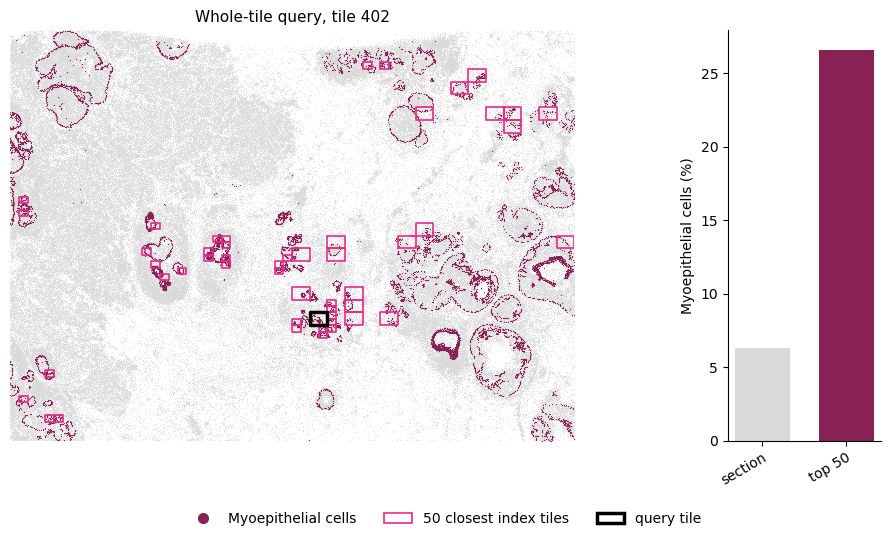

[np.float64(6.31485965213302), np.float64(26.610202875714005)]

In [10]:
d_whole = whole.distances(whole.query_vectors(covs[q]))
rows_whole = top_rows(d_whole)
niche = int(labels[rows_whole[0]])   # the query's niche = its closest index tile's
query_map(rows_whole, f"Whole-tile query, tile {q}", [QUERY_CLASS], query_tile=q)

## 2. Gene set from the tile: a block of the layout (Spindle-partial, d_B^S)

The block of the query's niche that holds most of the basal / myoepithelial signature's genes (the poster used the
myoepithelial block of its niche). Block 0 of a niche is its leftover genes and is not considered.

niche 3, block 12: 15 genes: EGFR, ACTA2, KRT16, SFRP1, KRT15, ACTG2, MYH11, PTN, KRT6B, DST, KRT5, MYLK, KRT14, HDC, PCLAF


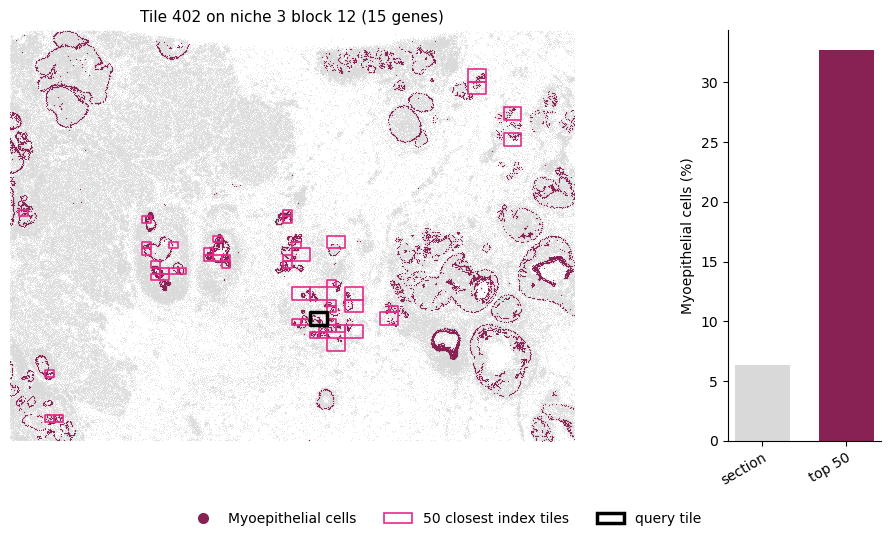

[np.float64(6.31485965213302), np.float64(32.72685922219695)]

In [11]:
MYO_GENES = ["KRT5", "KRT14", "ACTA2", "MYLK"]
perm = np.asarray(layout.perm_list[niche])
blocks = [perm[s:e] for s, e in layout.block_dict[niche]]
myo_idx, _, _ = sd.gene_indices(genes, MYO_GENES)
b = 1 + int(np.argmax([np.isin(g, myo_idx).sum() for g in blocks[1:]]))
block_genes = blocks[b]
print(f"niche {niche}, block {b}: {len(block_genes)} genes: {', '.join(genes[block_genes])}")

cov_s, idx = sd.tile_query(covs[q], block_genes)
rows_block = top_rows(part.distances(cov_s, idx))
query_map(rows_block, f"Tile {q} on niche {niche} block {b} ({len(idx)} genes)", [QUERY_CLASS], query_tile=q)

## 3. Gene set from the tile: a curated list

genes: ['KRT5', 'KRT14', 'ACTA2', 'MYLK'] | not index genes: []


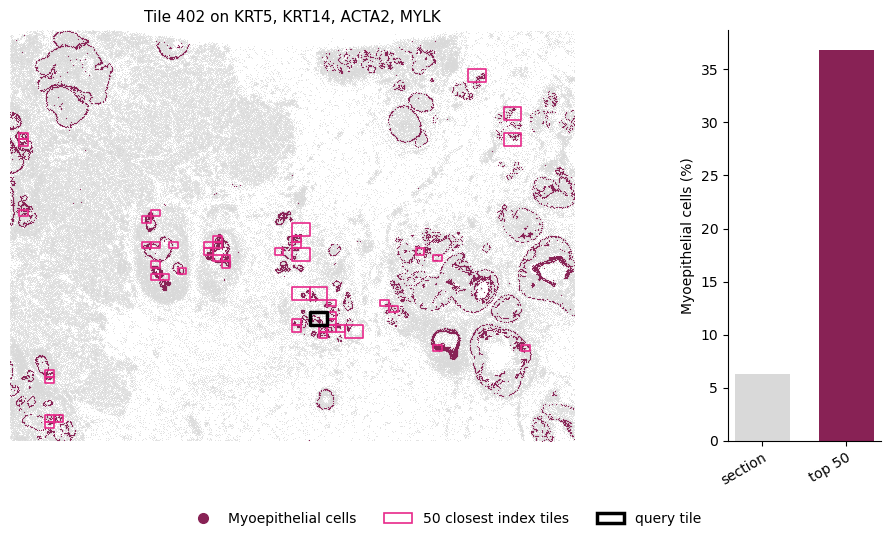

[np.float64(6.31485965213302), np.float64(36.83683683683684)]

In [12]:
idx, found, missing = sd.gene_indices(genes, MYO_GENES)
print("genes:", found, "| not index genes:", missing)
cov_s, idx = sd.tile_query(covs[q], idx)
rows_list = top_rows(part.distances(cov_s, idx))
query_map(rows_list, f"Tile {q} on {', '.join(found)}", [QUERY_CLASS], query_tile=q)

## 4. Gene list alone: template queries

Each breast signature (the curated lists of Fig 6F) as the Methods template: every pair of genes at correlation
ρ = 0.5, each variance the 90th percentile of that gene's variance over the index tiles. No query tile. Each map
highlights the signature's target cell class.

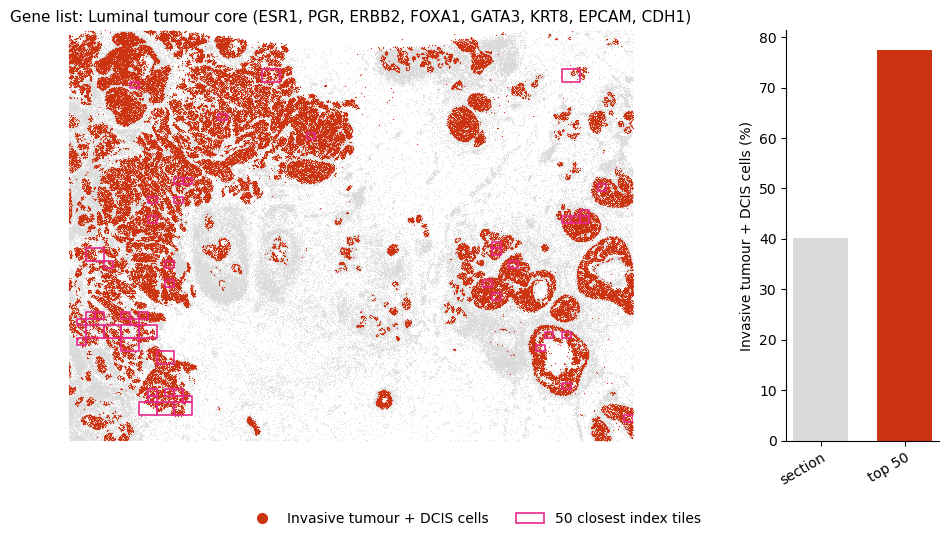

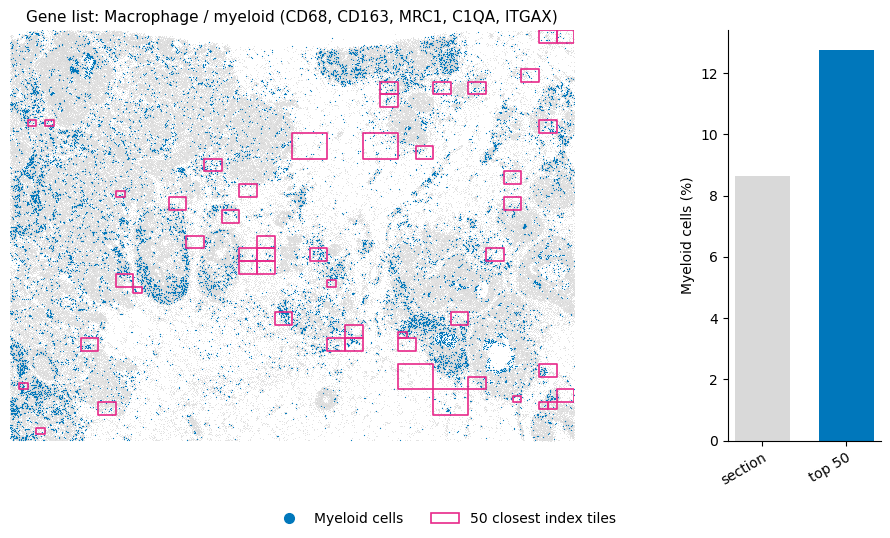

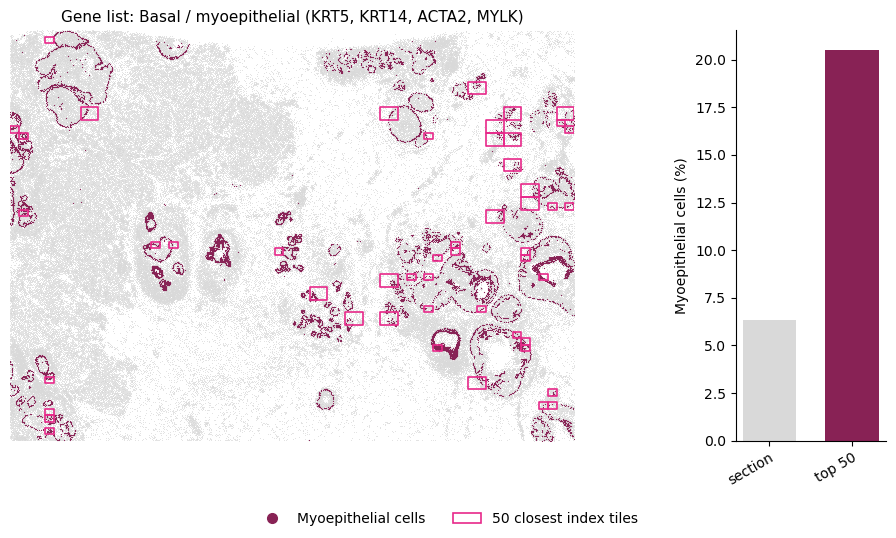

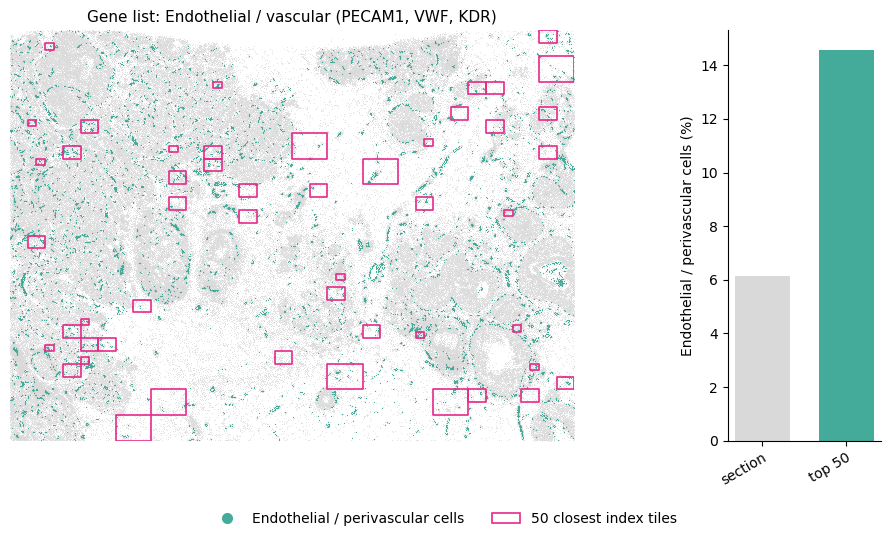

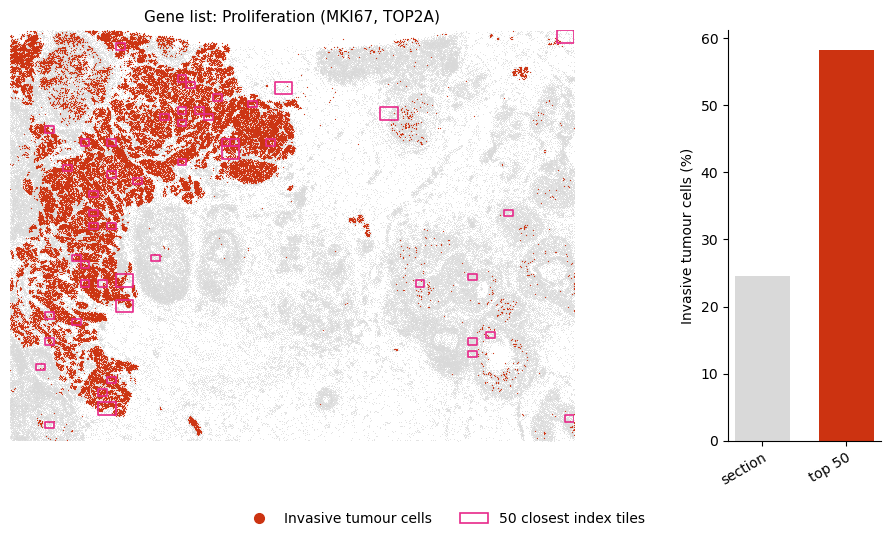

In [13]:
SIGNATURES = {
    "Luminal tumour core": (["ESR1", "PGR", "ERBB2", "FOXA1", "GATA3", "KRT8", "EPCAM", "CDH1"],
                            ["Invasive tumour", "DCIS"]),
    "Macrophage / myeloid": (["CD68", "CD163", "MRC1", "C1QA", "ITGAX"], ["Myeloid"]),
    "Basal / myoepithelial": (MYO_GENES, ["Myoepithelial"]),
    "Endothelial / vascular": (["PECAM1", "VWF", "KDR"], ["Endothelial / perivascular"]),
    "Proliferation": (["MKI67", "TOP2A"], ["Invasive tumour"]),
}
template_rows = {}
for name, (gl, target) in SIGNATURES.items():
    idx, found, missing = sd.gene_indices(genes, gl)
    if missing:
        print(f"{name}: not index genes {missing}")
    cov_t, idx = sd.template_query(omega, idx)
    template_rows[name] = top_rows(part.distances(cov_t, idx))
    query_map(template_rows[name], f"Gene list: {name} ({', '.join(found)})", target)

## Overlap of the top tiles between the tile-derived queries

In [14]:
def jaccard(a, b):
    a, b = set(a[:TOP].tolist()), set(b[:TOP].tolist())
    return len(a & b) / len(a | b)


sets = {"whole tile": rows_whole, "block": rows_block, "curated list": rows_list,
        "template (basal / myo)": template_rows["Basal / myoepithelial"]}
names = list(sets)
J = np.array([[jaccard(sets[a], sets[b]) for b in names] for a in names])
print(f"Jaccard of the top {TOP}")
print(" " * 24 + "".join(f"{n[:12]:>14}" for n in names))
for n, row in zip(names, J):
    print(f"{n:<24}" + "".join(f"{v:14.2f}" for v in row))

Jaccard of the top 50
                            whole tile         block  curated list  template (ba
whole tile                        1.00          0.41          0.30          0.05
block                             0.41          1.00          0.47          0.09
curated list                      0.30          0.47          1.00          0.15
template (basal / myo)            0.05          0.09          0.15          1.00
